In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve
import math

In [ ]:
#Se resuelve el inc A)
def ghost_at_b(f, a, b, ua, uxb, n):
  """
  Resuelve u''(x) = f(x); a<x<b , u(a) = ua, u'(b)= uxb
  usando diferencias centradas y un punto fantasma en x_{n+1} = b + h
  Devuelve: x : array con los n+1 nodos x_0,...,x_n
            U : array con la solucion aproximada U_0,...,U_n
  """
  h = (b - a) / n
  x = np.linspace(a, b, n + 1)
#Diagonales
  x = []
  for i in range(n + 1):
        x.append(a + i * h)

  diagonal_medio = []
  for i in range(n):
        diagonal_medio.append(-2)
  diagonal_medio[n - 1] = -1

  diagonal_arriba = []
  diagonal_abajo = []
  for i in range(n - 1):
        diagonal_arriba.append(1)
        diagonal_abajo.append(1)

  A = diags([diagonal_abajo, diagonal_medio, diagonal_arriba],
              offsets=[-1, 0, 1], format='csr')
  #El lado derecho de F
  F = []
  for i in range(1, n + 1):
        F.append(h**2 * f(x[i]))

  F[0] = F[0] - ua                          # ajuste por Dirichlet en a
  F[n - 1] = (h**2 / 2) * f(x[n]) - h * uxb  # ajuste por Neumann + ghost

#Se resuelve el sistema
  U_interior = spsolve(A, F)

    # Se agrega el dato conocido U_0 = ua al principio
  U = [ua] + list(U_interior)

  return x, U



In [ ]:
#Se plantea el inc B)
if __name__ == "__main__":
    f = lambda x: -math.pi**2 * math.cos(math.pi * x)
    x, U = ghost_at_b(f, a=0.0, b=0.5, ua=1.0, uxb=-math.pi, n=50)

    # solucion exacta conocida
    u_exacta = []
    for xi in x:
        u_exacta.append(math.cos(math.pi * xi))

    # el error puntual en cada nodo:
    error = []
    for i in range(len(x)):
        error.append(abs(U[i] - u_exacta[i]))

    print("Error maximo:", max(error))

Error maximo: 0.00021144570691410561


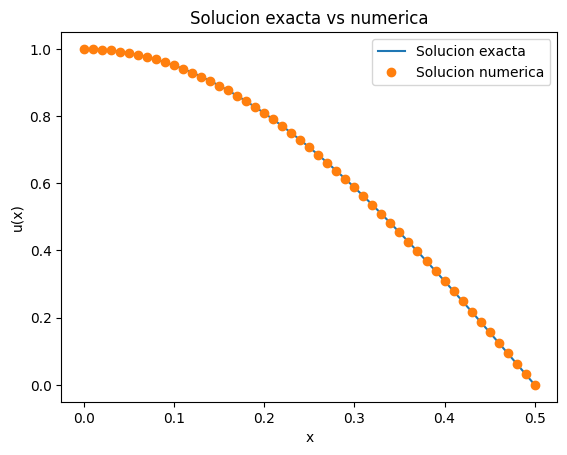

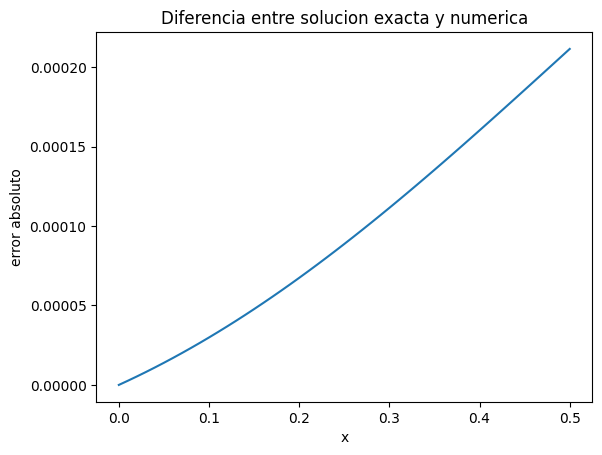

In [ ]:
#se resuelve el inc C)
plt.figure()
plt.plot(x, u_exacta, '-', label='Solucion exacta')
plt.plot(x, U, 'o', label='Solucion numerica')
plt.xlabel('x')
plt.ylabel('u(x)')
plt.title('Solucion exacta vs numerica')
plt.legend()
plt.savefig('solucion.png')

#grafico 2:
plt.figure()
plt.plot(x, error, '-')
plt.xlabel('x')
plt.ylabel('error absoluto')
plt.title('Diferencia entre solucion exacta y numerica')
plt.savefig('error.png')

plt.show()